In [3]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")

In [ ]:
pip install xgboost

In [4]:
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

sys.path.insert(0, str(BASE_DIR / "src"))

print("Project directory:", BASE_DIR)

Project directory: d:\RetailMind


In [6]:
cleaned_files = [
    file for file in BASE_DIR.rglob("*.csv")
    if file.name.lower() == "cleaned_data.csv"
]

if not cleaned_files:
    raise FileNotFoundError("cleaneddata.csv was not found.")

CLEANED_DATA_PATH = cleaned_files[0]

df = pd.read_csv(CLEANED_DATA_PATH)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
X = df.drop(columns=["customerID", "Churn"])

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (5634, 19)
Testing shape: (1409, 19)


In [9]:
DAY3_MODEL_PATH = BASE_DIR / "models" / "churn_v3.joblib"

day3_model = joblib.load(DAY3_MODEL_PATH)

print("Day 3 model loaded successfully.")

Day 3 model loaded successfully.


In [10]:
day3_predictions = day3_model.predict(X_test)

day3_probabilities = day3_model.predict_proba(X_test)[:, 1]

day3_metrics = {
    "Model": "Day 3 Random Forest",
    "Accuracy": accuracy_score(y_test, day3_predictions),
    "Precision": precision_score(y_test, day3_predictions),
    "Recall": recall_score(y_test, day3_predictions),
    "F1 Score": f1_score(y_test, day3_predictions),
    "ROC-AUC": roc_auc_score(y_test, day3_probabilities)
}

baseline_df = pd.DataFrame([day3_metrics])

baseline_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Day 3 Random Forest,0.685593,0.45036,0.836898,0.585594,0.810609


In [11]:
def engineer_features(data):
    data = data.copy()

    # 1. Tenure-based features
    data["TenureGroup"] = pd.cut(
        data["tenure"],
        bins=[-1, 12, 24, 48, 60, float("inf")],
        labels=[
            "New",
            "Short-Term",
            "Medium-Term",
            "Long-Term",
            "Loyal"
        ]
    )

    data["IsNewCustomer"] = (data["tenure"] <= 12).astype(int)

    data["IsLongTermCustomer"] = (data["tenure"] >= 48).astype(int)

    # 2. Charge-based features
    data["AverageMonthlyCharge"] = (
        data["TotalCharges"] / data["tenure"].replace(0, np.nan)
    )

    data["ChargeRatio"] = (
        data["TotalCharges"] /
        (data["MonthlyCharges"] * data["tenure"]).replace(0, np.nan)
    )

    # 3. Service-based features
    service_columns = [
        "PhoneService",
        "MultipleLines",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies"
    ]

    data["ServiceCount"] = (
        data[service_columns] == "Yes"
    ).sum(axis=1)

    data["UsesMultipleServices"] = (
        data["ServiceCount"] >= 3
    ).astype(int)

    # 4. Contract-based features
    data["IsMonthToMonth"] = (
        data["Contract"] == "Month-to-month"
    ).astype(int)

    data["HasLongTermContract"] = (
        data["Contract"].isin(["One year", "Two year"])
    ).astype(int)

    data["UsesElectronicBilling"] = (
        data["PaperlessBilling"] == "Yes"
    ).astype(int)

    return data

In [12]:
X_train_engineered = engineer_features(X_train)
X_test_engineered = engineer_features(X_test)

print("Original feature count:", X_train.shape[1])
print("Engineered feature count:", X_train_engineered.shape[1])

print("\nNew features:")
print(
    list(
        set(X_train_engineered.columns) - set(X_train.columns)
    )
)

Original feature count: 19
Engineered feature count: 29

New features:
['IsMonthToMonth', 'ChargeRatio', 'UsesElectronicBilling', 'IsNewCustomer', 'TenureGroup', 'AverageMonthlyCharge', 'UsesMultipleServices', 'HasLongTermContract', 'ServiceCount', 'IsLongTermCustomer']


In [13]:
X_train_engineered.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TenureGroup,IsNewCustomer,IsLongTermCustomer,AverageMonthlyCharge,ChargeRatio,ServiceCount,UsesMultipleServices,IsMonthToMonth,HasLongTermContract,UsesElectronicBilling
3738,Male,0,No,No,35,No,No phone service,DSL,No,No,...,Medium-Term,0,0,48.618571,0.988182,3,1,1,0,0
3151,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,...,Short-Term,0,0,76.770000,1.022237,2,0,1,0,0
4860,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,...,Short-Term,0,0,45.411538,1.119890,3,1,0,1,0
3867,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,...,Medium-Term,0,0,73.296154,0.997227,5,1,0,1,1
3810,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,...,New,1,0,44.550000,1.000000,1,0,1,0,0


In [14]:
engineered_columns = [
    "AverageMonthlyCharge",
    "ChargeRatio"
]

X_train_engineered[engineered_columns].describe()

,AverageMonthlyCharge,ChargeRatio
count,5626.000000,5626.000000
mean,64.970975,1.000579
std,30.224385,0.051152
min,13.828571,0.689356
25%,36.240000,0.979723
50%,70.600000,1.000000
75%,90.508234,1.019332
max,121.400000,1.530934


In [15]:
print(
    X_train_engineered[engineered_columns]
    .isnull()
    .sum()
)

AverageMonthlyCharge    8
ChargeRatio             8
dtype: int64


In [19]:
# Extract the fitted preprocessing transformer
preprocessor = day3_model.named_steps["preprocessor"]

# Get feature names after preprocessing
transformed_features = preprocessor.get_feature_names_out()

# Get feature importance from the Random Forest
feature_importances = (
    day3_model.named_steps["classifier"].feature_importances_
)

# Create importance DataFrame
importance_df = pd.DataFrame({
    "Feature": transformed_features,
    "Importance": feature_importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

importance_df.head(15)

,Feature,Importance
0,categorical__Contract_Two year,0.085608
1,categorical__StreamingTV_No internet service,0.066201
2,categorical__OnlineSecurity_No,0.050041
3,numeric__tenure,0.048931
4,categorical__OnlineBackup_No,0.046429
5,categorical__InternetService_No,0.043253
6,categorical__InternetService_Fiber optic,0.040380
7,categorical__DeviceProtection_No internet service,0.038494
8,categorical__Contract_One year,0.033443
9,categorical__TechSupport_Yes,0.032987


In [20]:
selected_mask = feature_selector.get_support()

selected_features = transformed_features[selected_mask]

print("Total transformed features:", len(transformed_features))
print("Selected features:", len(selected_features))

print("\nSelected features:")
print(selected_features.tolist())

Total transformed features: 5320
Selected features: 5320

Selected features:
['numeric__SeniorCitizen', 'numeric__tenure', 'numeric__MonthlyCharges', 'categorical__gender_Female', 'categorical__gender_Male', 'categorical__Partner_No', 'categorical__Partner_Yes', 'categorical__Dependents_No', 'categorical__Dependents_Yes', 'categorical__PhoneService_No', 'categorical__PhoneService_Yes', 'categorical__MultipleLines_No', 'categorical__MultipleLines_No phone service', 'categorical__MultipleLines_Yes', 'categorical__InternetService_DSL', 'categorical__InternetService_Fiber optic', 'categorical__InternetService_No', 'categorical__OnlineSecurity_No', 'categorical__OnlineSecurity_No internet service', 'categorical__OnlineSecurity_Yes', 'categorical__OnlineBackup_No', 'categorical__OnlineBackup_No internet service', 'categorical__OnlineBackup_Yes', 'categorical__DeviceProtection_No', 'categorical__DeviceProtection_No internet service', 'categorical__DeviceProtection_Yes', 'categorical__TechSupp

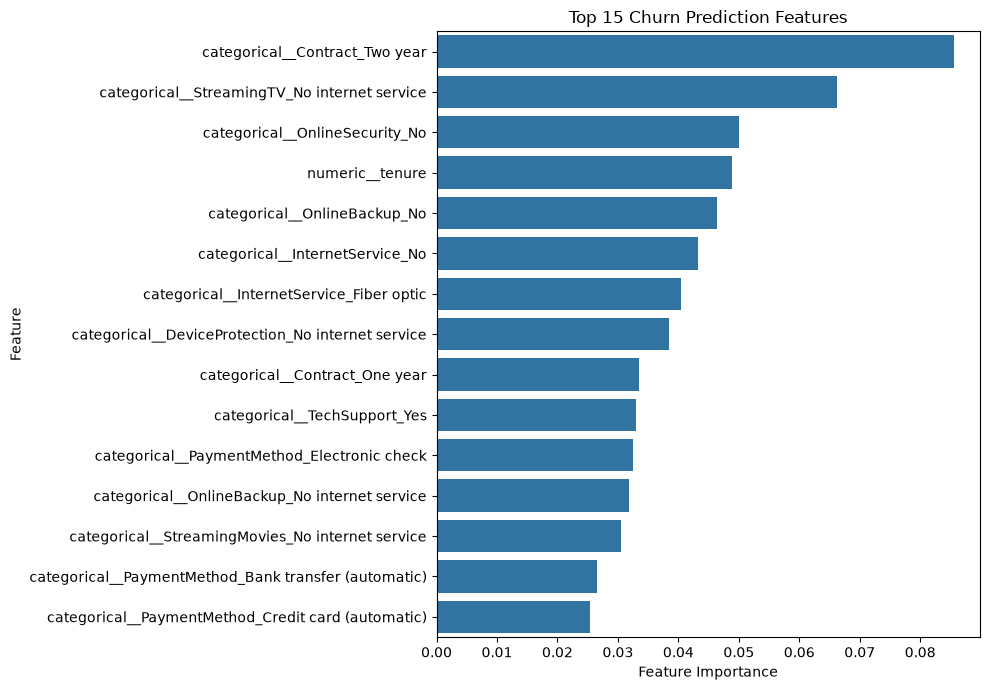

In [21]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Churn Prediction Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_features = X_train_engineered.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train_engineered.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [23]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [24]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

In [25]:
rf_pipeline.fit(X_train_engineered, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [26]:
xgb_pipeline.fit(X_train_engineered, y_train)

print("XGBoost training completed.")

XGBoost training completed.


In [27]:
rf_predictions = rf_pipeline.predict(X_test_engineered)
rf_probabilities = rf_pipeline.predict_proba(X_test_engineered)[:, 1]

xgb_predictions = xgb_pipeline.predict(X_test_engineered)
xgb_probabilities = xgb_pipeline.predict_proba(X_test_engineered)[:, 1]

In [28]:
def evaluate_model(name, y_true, predictions, probabilities):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1 Score": f1_score(y_true, predictions),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

day4_results = [
    evaluate_model(
        "Day 3 Random Forest",
        y_test,
        day3_predictions,
        day3_probabilities
    ),
    evaluate_model(
        "Day 4 Random Forest",
        y_test,
        rf_predictions,
        rf_probabilities
    ),
    evaluate_model(
        "Day 4 XGBoost",
        y_test,
        xgb_predictions,
        xgb_probabilities
    )
]

day4_comparison_df = pd.DataFrame(day4_results)

day4_comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Day 3 Random Forest,0.685593,0.450360,0.836898,0.585594,0.810609
1,Day 4 Random Forest,0.764372,0.537906,0.796791,0.642241,0.841742
2,Day 4 XGBoost,0.796309,0.649485,0.505348,0.568421,0.840674


In [29]:
day4_comparison_df = day4_comparison_df.sort_values(
    by=["Recall", "F1 Score", "ROC-AUC"],
    ascending=False
).reset_index(drop=True)

day4_comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Day 3 Random Forest,0.685593,0.450360,0.836898,0.585594,0.810609
1,Day 4 Random Forest,0.764372,0.537906,0.796791,0.642241,0.841742
2,Day 4 XGBoost,0.796309,0.649485,0.505348,0.568421,0.840674


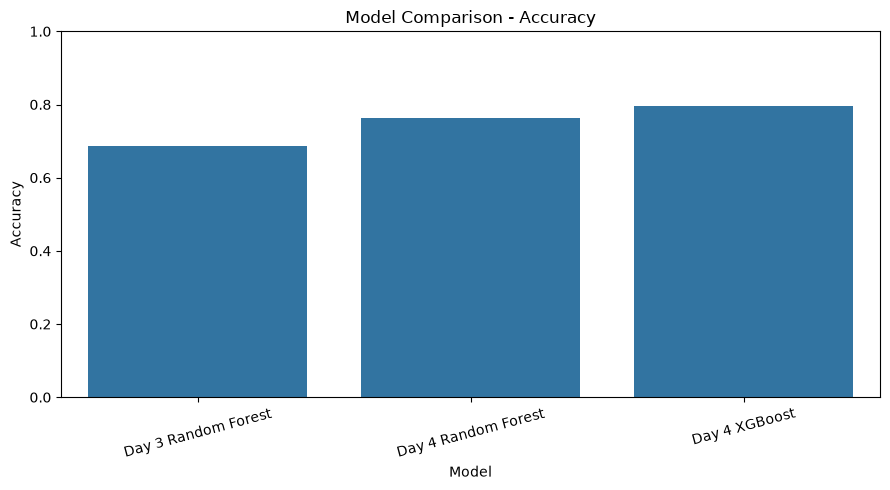

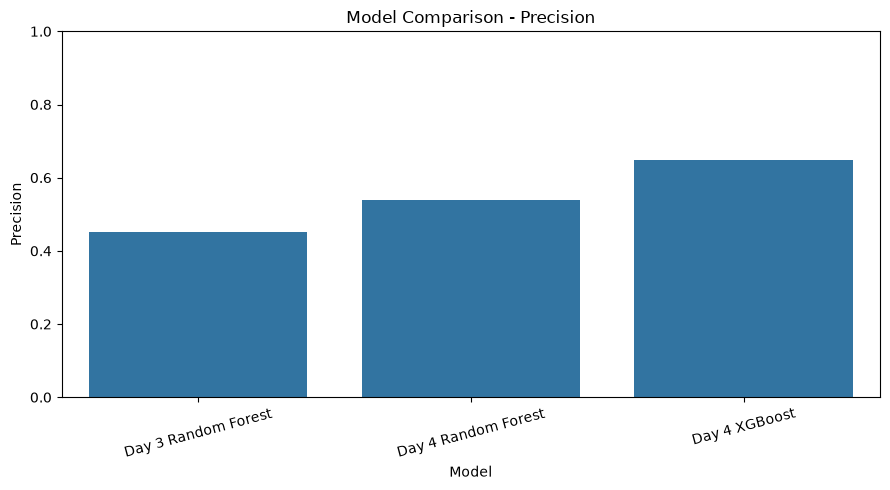

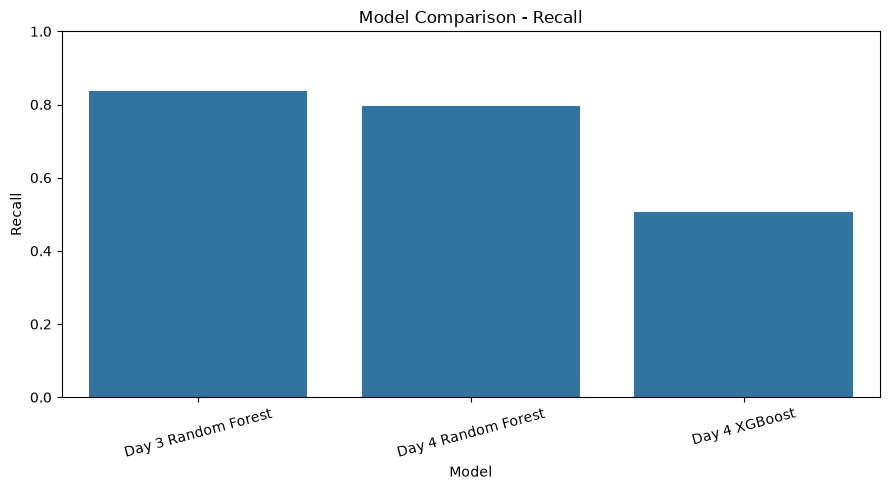

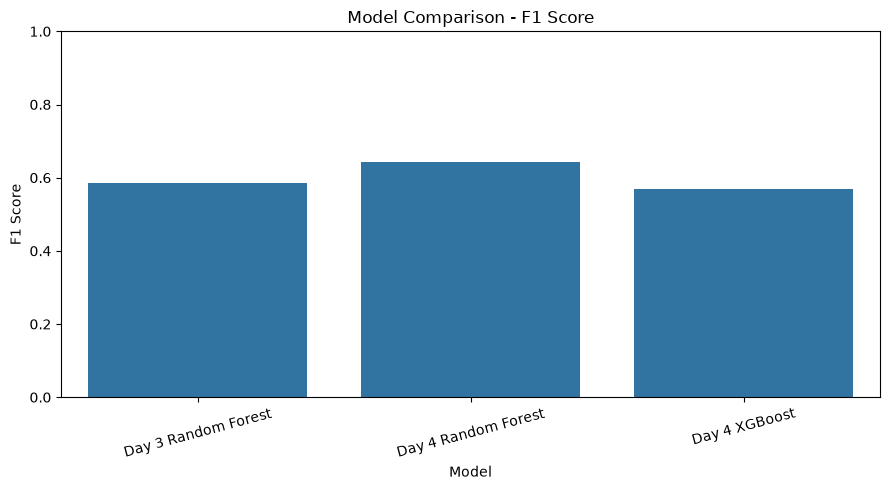

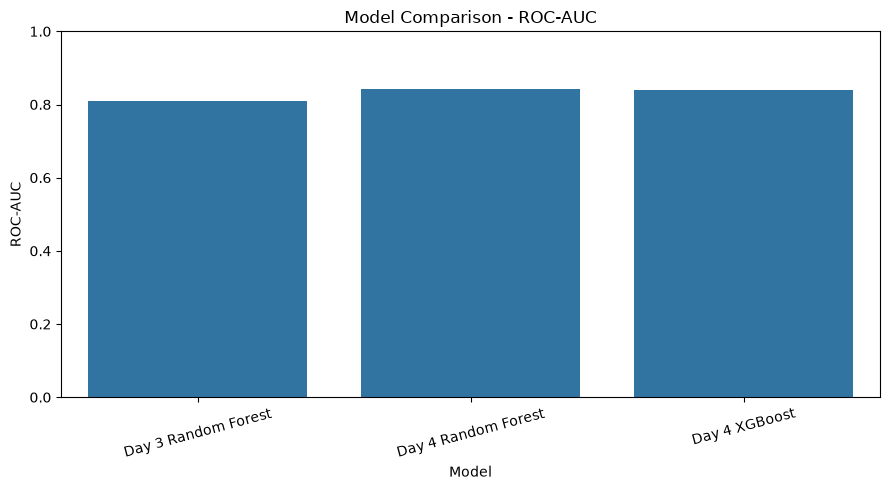

In [30]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

for metric in metrics_to_plot:
    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=day4_comparison_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xticks(rotation=15)
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

In [31]:
best_model_name = day4_comparison_df.iloc[0]["Model"]

model_mapping = {
    "Day 3 Random Forest": day3_model,
    "Day 4 Random Forest": rf_pipeline,
    "Day 4 XGBoost": xgb_pipeline
}

best_model = model_mapping[best_model_name]

print("Selected champion:", best_model_name)

Selected champion: Day 3 Random Forest


In [32]:
MODEL_PATH = BASE_DIR / "models" / "churn_v4.joblib"

MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(best_model, MODEL_PATH)

print("Day 4 model saved:", MODEL_PATH)

Day 4 model saved: d:\RetailMind\models\churn_v4.joblib


In [33]:
REPORT_PATH = BASE_DIR / "reports" / "day4_model_comparison.csv"

REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)

day4_comparison_df.to_csv(
    REPORT_PATH,
    index=False
)

print("Comparison report saved:", REPORT_PATH)

Comparison report saved: d:\RetailMind\reports\day4_model_comparison.csv


In [34]:
best_predictions = best_model.predict(X_test_engineered)

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.91      0.63      0.75      1035
       Churn       0.45      0.84      0.59       374

    accuracy                           0.69      1409
   macro avg       0.68      0.73      0.67      1409
weighted avg       0.79      0.69      0.70      1409



In [35]:
if best_model_name == "Day 3 Random Forest":
    best_predictions = best_model.predict(X_test)
else:
    best_predictions = best_model.predict(X_test_engineered)